# Part 2: Cleaning

The fixed rules that turn the raw survey answers into the input of part 3, and checks that they are right. The rules live in `p1/cleaning.py`, so `run.py` can rebuild the clean data without this notebook. They come from the BRFSS 2015 codebook and learn nothing from the data, so train and test are cleaned alike; steps that learn from the data (one-hot encoding, imputation, scaling) are part-3 transforms. The reason for each rule is in `docs/eda_findings.md`, sections 4 and 5.

In [1]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np

from p1 import cleaning, eda
from p1.cleaning import build_clean_dataset, clean
from p1.data import load_clean, load_raw

eda.use_style()
ds = load_raw()
x, y, names = ds.x_train, ds.y_train, ds.feature_names
x_clean, clean_names = clean(x, names)
x_test_clean, _ = clean(ds.x_test, names)


def raw(name, data=x):
    """Column `name` of the raw training features (or of `data`)."""
    return data[:, names.index(name)]


def cleaned(name, data=x_clean):
    """Column `name` of the clean training features (or of `data`)."""
    return data[:, clean_names.index(name)]

## 1. What the rules do

In [2]:
converted = {
    "BLDSUGAR": "times per year",
    "FEETCHK2": "times per year",
    "LONGWTCH": "years",
    "FLSHTMY2": "months before the interview",
    "HIVTSTD3": "months before the interview",
}
# Numeric features where some NaNs became values: the skipped questions.
filled = [
    n for n in cleaning.NUMERIC if (np.isnan(raw(n)) & ~np.isnan(cleaned(n))).any()
]
n_categorical = len(clean_names) - len(cleaning.NUMERIC)
eda.print_table(
    ["rule", "features"],
    [
        (
            "drop: survey design (ids, interview dates, weights)",
            len(cleaning.SURVEY_DESIGN),
        ),
        ("drop: exact copies of other columns", len(cleaning.EXACT_COPIES)),
        (
            "drop: mixed units, replaced by the CDC's conversion",
            len(cleaning.MIXED_UNITS),
        ),
        ("numeric: special codes -> 0 or NaN", len(cleaning.CODES)),
        ("numeric: converted to one unit", len(converted)),
        ("numeric: skipped questions -> implied value", len(filled)),
        ("categorical: codes kept for one-hot encoding", n_categorical),
    ],
)
print(
    f"\n{len(names)} raw features -> {len(clean_names)} clean: "
    f"{len(cleaning.NUMERIC)} numeric, {n_categorical} categorical"
)

rule                                                 features
drop: survey design (ids, interview dates, weights)        14
drop: exact copies of other columns                         2
drop: mixed units, replaced by the CDC's conversion        14
numeric: special codes -> 0 or NaN                         26
numeric: converted to one unit                              5
numeric: skipped questions -> implied value                14
categorical: codes kept for one-hot encoding              235

321 raw features -> 291 clean: 56 numeric, 235 categorical


- **Dropped (30).** 14 columns describe the survey rather than the person (record ids, interview dates, sampling strata and weights), 2 are exact copies of other columns, and 14 raw answers pack a unit into the number (`ALCDAY5` is 1xx days per week or 2xx days per month; `WEIGHT2` is in pounds, or in kilograms when it starts with 9). The CDC converted each of these to one unit (`DROCDY3_`, `WTKG3`, ...), and those versions are kept.
- **Numeric answers (56) become quantities.** "None" codes (88, 888) become 0, "don't know" and "refused" become NaN (`cleaning.CODES`). Three answers that mix units without a CDC version are converted to times per year or years, and two dates (MMYYYY) to months before the interview. Questions the survey skips because the answer is implied get that answer: 0 days of poor health when every day was good, 0 drinks for people who did not drink, 0 minutes of exercise for people who did not exercise.
- **Categorical answers (235) keep their codes.** "Don't know" often behaves like "yes" (EDA, section 3), and part 3 one-hot encodes every code, NaN included. Sparse features are kept too, `HAREHAB1` above all (the label leak of the EDA, section 4).
- `cleaning.NUMERIC` tells part 3 which features to use as numbers. `cleaning.HEAVY_TAILED` marks the 33 of them that count times, drinks, visits, servings or minutes: a few respondents report huge values (up to 54,000 minutes of exercise a week), so part 3 can log-transform them.

## 2. The rules hold on the data

In [3]:
rules = [
    (
        "POORHLTH",
        "PHYSHLTH = MENTHLTH = 88 (no bad day)",
        (raw("PHYSHLTH") == 88) & (raw("MENTHLTH") == 88),
    ),
    ("AVEDRNK2", "ALCDAY5 = 888 (no drink)", raw("ALCDAY5") == 888),
    ("PA1MIN_", "EXERANY2 = 2 (no exercise)", raw("EXERANY2") == 2),
    ("PAFREQ2_", "EXRACT21 = 88 (no second activity)", raw("EXRACT21") == 88),
]
rows = []
for name, condition, skipped in rules:
    rows.append(
        (
            name,
            condition,
            f"{skipped.mean():.1%}",
            f"{np.isnan(raw(name)[skipped]).mean():.0%}",
            f"{np.isnan(raw(name)).mean():.1%}",
            f"{np.isnan(cleaned(name)).mean():.1%}",
        )
    )
eda.print_table(
    ["feature", "skipped when", "rows", "blank then", "NaN before", "NaN after"],
    rows,
    "llrrrr",
)

left = sum(
    np.isin(cleaned(n), list(codes)).sum() for n, codes in cleaning.CODES.items()
)
print(f"\nspecial codes left in the {len(cleaning.CODES)} recoded features: {left}\n")

rows = []
for name, unit in converted.items():
    values = cleaned(name)[~np.isnan(cleaned(name))]
    rows.append(
        (
            name,
            unit,
            f"{np.median(values):.3g}",
            f"{values.max():,.0f}",
            f"{np.isnan(cleaned(name)).mean():.1%}",
        )
    )
eda.print_table(["converted", "unit", "median", "max", "NaN"], rows, "llrrr")

gap = np.abs(eda.missing_fraction(x_clean) - eda.missing_fraction(x_test_clean)).max()
print(f"\nlargest train-test gap in the NaN rate of a clean feature: {gap:.4f}")
print(
    f"test rows that answered HAREHAB1: {(~np.isnan(cleaned('HAREHAB1', x_test_clean))).sum()}"
)

feature   skipped when                            rows  blank then  NaN before  NaN after
POORHLTH  PHYSHLTH = MENTHLTH = 88 (no bad day)  48.7%        100%       48.7%       1.1%
AVEDRNK2  ALCDAY5 = 888 (no drink)               47.1%        100%       52.1%       5.8%
PA1MIN_   EXERANY2 = 2 (no exercise)             24.3%        100%       34.4%      10.1%
PAFREQ2_  EXRACT21 = 88 (no second activity)     20.9%        100%       55.7%      10.6%

special codes left in the 26 recoded features: 0

converted  unit                         median     max    NaN
BLDSUGAR   times per year                  365  36,135  93.5%
FEETCHK2   times per year                  365  36,135  93.6%
LONGWTCH   years                             5      99  94.6%
FLSHTMY2   months before the interview       5      13  59.4%
HIVTSTD3   months before the interview      44     371  79.7%

largest train-test gap in the NaN rate of a clean feature: 0.0040
test rows that answered HAREHAB1: 238


- The skip rules are exact, not guesses: in the rows where the codebook says a question is skipped, it is always blank ("blank then" = 100%), and filling these rows removes most NaNs of the feature. The NaNs left are "don't know", "refused" or interrupted interviews; part 3 flags them with NaN indicators.
- No special code is left in the recoded features, and the converted features have plausible ranges. A few answers stay extreme but are valid codes (98 blood-sugar checks a day, 77 children), so they are kept; a log transform tames them.
- Train and test are cleaned alike: same columns and the same NaN rates (gap ≤ 0.004), and the 238 test respondents who answered `HAREHAB1` keep their answer.

## 3. What the cleaning is worth

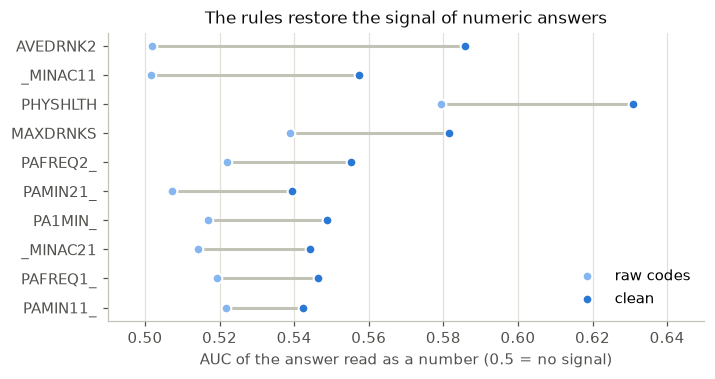

model on the 56 numeric features only    AUC  best F1
raw codes                              0.795    0.332
clean                                  0.803    0.342


In [4]:
numeric_raw = x[:, [names.index(n) for n in cleaning.NUMERIC]]
numeric_clean = x_clean[:, [clean_names.index(n) for n in cleaning.NUMERIC]]
_, auc_raw = eda.univariate_auc(numeric_raw, y)
_, auc_clean = eda.univariate_auc(numeric_clean, y)
top = np.argsort(auc_clean - auc_raw)[-10:]  # largest gains, the largest on top

fig, ax = plt.subplots(figsize=(7, 3.4))
rows = np.arange(len(top))
ax.hlines(rows, auc_raw[top], auc_clean[top], color="#c3c2b7", lw=2, zorder=1)
for auc, color, label in [
    (auc_raw, eda.BLUE_LIGHT, "raw codes"),
    (auc_clean, eda.BLUE, "clean"),
]:
    ax.scatter(
        auc[top],
        rows,
        s=40,
        color=color,
        edgecolor="white",
        linewidth=1.3,
        zorder=2,
        label=label,
    )
ax.set_yticks(rows, [cleaning.NUMERIC[j] for j in top])
ax.set(
    xlim=(0.49, 0.65),
    xlabel="AUC of the answer read as a number (0.5 = no signal)",
    title="The rules restore the signal of numeric answers",
)
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
eda.save_figure(fig, "clean_numeric_auc")
plt.show()

train, valid = np.split(
    np.random.default_rng(0).permutation(len(y)), [int(0.8 * len(y))]
)


def numeric_probe(data):
    """AUC and best F1 of a ridge probe; NaN -> training median, plus NaN indicators."""
    nan = np.isnan(data)
    filled = np.where(nan, np.nanmedian(data[train], axis=0), data)
    features = np.hstack([filled, nan[:, nan[train].any(axis=0)]])
    score = eda.ridge_probe(features[train], y[train], features[valid])
    return eda.roc_auc(score, y[valid]), eda.f1_by_threshold(score, y[valid])[3].max()


eda.print_table(
    [f"model on the {len(cleaning.NUMERIC)} numeric features only", "AUC", "best F1"],
    [
        ("raw codes", *numeric_probe(numeric_raw)),
        ("clean", *numeric_probe(numeric_clean)),
    ],
)

- Each dot is the AUC of one feature used directly as a score, which is what a linear model sees (0.5 = no signal). Read as numbers, the codes hide the signal: "none" (88) becomes the largest number of bad days, and the non-drinkers and non-exercisers get the median amount. After cleaning, drinks per drinking day go from no signal (0.50) to 0.59, the days of poor physical health from 0.58 to 0.63, and the weekly exercise amounts from about 0.51 to 0.55.
- A linear model on the numeric features alone gains about 0.01 AUC and F1 (ridge probe on an 80/20 split).
- In the full encoding of the EDA (categorical answers one-hot, numeric features with NaN indicators), the cleaning no longer changes the score. In our tests (logistic regression, outside this notebook), 5-fold F1 is 0.4404 ± 0.0021 with the raw numeric codes and 0.4401 ± 0.0018 with the clean ones (paired difference −0.0003 ± 0.0009, AUC 0.864 for both). The one-hot encoded answers carry what the codes hid: the gate questions (`EXERANY2`, `DRNKANY5`) and the CDC's recodes (`_PACAT1`, `_RFDRHV5`, ...). The cleaning is not where the score comes from; it makes the numeric features mean what they say, which matters for models that use them as numbers and for reading the weights.
- The EDA's gain from "cleaning the codes" (F1 0.417 → 0.433 with every feature read as a number) came from turning the "don't know" and "refused" codes of the categorical answers into NaN. One-hot encoding makes that unnecessary and keeps those codes as information, so part 2 leaves them in place.

## Summary for part 3

- Load the data with `load_clean()`: 291 features, train and test cleaned alike.
- Use the features of `cleaning.NUMERIC` as numbers: NaN indicator plus median imputation, then standardization; `log1p` for those of `cleaning.HEAVY_TAILED` is optional (it changed F1 by less than 0.001). One-hot encode all other features, with a column for NaN.
- This reproduces the EDA's best encoding: logistic regression reached a 5-fold F1 of 0.440 ± 0.002 (AUC 0.864) on the clean data.

## 4. Write the clean dataset

Saves `data/processed/clean.npz`, the input of part 3. Run it again after every change to `p1/cleaning.py`: `load_clean` warns when the file is older than the rules.

In [5]:
build_clean_dataset()
clean_ds = load_clean()
print(f"clean.npz: train {clean_ds.x_train.shape}, test {clean_ds.x_test.shape}")

clean.npz: train (328135, 291), test (109379, 291)
